# Ames Housing Price Prediction — Model Evaluation and Optimization

## Objective

After training my initial XGBoost regression model, I observed a substantial difference between its training RMSE ($6,593.23) and validation RMSE ($25,238.52). This suggested potential overfitting, as the model performed considerably better on training data than on unseen observations.

To investigate this, I implemented 5-fold cross-validation to assess generalization performance, followed by GridSearchCV to identify potentially better hyperparameter configurations.

Finally, I conducted residual analysis to investigate large prediction errors, identify potential patterns in overprediction and underprediction, and determine opportunities for further model improvement.

In [21]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /Users/sinjinkim/Documents/ames-housing-price-prediction


In [22]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Model evaluation
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score
)

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor

# Your project modules
from src.features import build_preprocessor
from src.train import build_model, tune_model
from src.evaluate import evaluate_model, residual_analysis

## Data Preparation 

The original Ames Housing dataset contains 1,460 observations. I reserved 20% of the dataset for validation and used the remaining 80% for model traning and cross validation. I also fixed a random seed to esure reproducibility

In [37]:
data = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "train.csv"
)

X = data.drop(columns=["SalePrice", "Id"])
y = data["SalePrice"]

train_X, val_X, train_y, val_y = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Dataset shape:", data.shape)
print("Training features:", train_X.shape)
print("Validation features:", val_X.shape)
print("Training target:", train_y.shape)
print("SalePrice in features:", "SalePrice" in train_X.columns)

Dataset shape: (1460, 81)
Training features: (1168, 79)
Validation features: (292, 79)
Training target: (1168,)
SalePrice in features: False


## Initial XGBoost Model 

The model uses a preprocessing pipeline to handle missing values and categorical variables before fitting an XGBoost regressor. 

In [38]:
pipeline = Pipeline(steps=[
    ("preprocessor", build_preprocessor(train_X)),
    ("model", build_model())
])

print(pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('zero_impute',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['MasVnrArea',
                                                   'GarageYrBlt']),
                                                 ('numerical', SimpleImputer(),
                                                  ['MSSubClass', 'LotFrontage',
                                                   'LotArea', 'OverallQual',
                                                   'OverallCond', 'YearBuilt',
                                                   'YearRemodAdd', 'BsmtFinSF1',
                                                   'BsmtFinSF2', 'BsmtUnfSF',
                                                   'TotalBsmtSF', '1stFlrSF',
                                                   '

In [39]:
pipeline.fit(train_X, train_y)

train_rmse, train_mae = evaluate_model(
    pipeline,
    train_X,
    train_y
)

val_rmse, val_mae = evaluate_model(
    pipeline,
    val_X,
    val_y
)

print(f"Training RMSE: ${train_rmse:.2f}")
print(f"Training MAE: ${train_mae:.2f}")

print(f"Validation RMSE: ${val_rmse:.2f}")
print(f"Validation MAE: ${val_mae:.2f}")

Training RMSE: $6673.84
Training MAE: $4837.15
Validation RMSE: $25440.83
Validation MAE: $16282.43


## Baseline Moel Comparison 

To determine whether XGBoost provides predictive value, I compared its performance against an empty model using DummyRegressor. This mdoel preidcts the mean sale price from its training data for every observation.

In [42]:
baseline = DummyRegressor(strategy="mean")

baseline.fit(train_X, train_y)

baseline_rmse, baseline_mae = evaluate_model(
    baseline,
    val_X,
    val_y
)

baseline_comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "XGBoost"],
    "Validation RMSE": [baseline_rmse, val_rmse],
    "Validation MAE": [baseline_mae, val_mae]
})

baseline_comparison

,Model,Validation RMSE,Validation MAE
0,Mean Baseline,87619.034506,62575.926452
1,XGBoost,25440.828125,16282.427734


## Five Fold Cross Validation


Since the original model showed a substantial training to validation performance gap, I implemented a 5 fold cross validation to evaluate how consistently the model generalizes across different training subsets

In [43]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=31
)

cv_scores = cross_val_score(
    pipeline,
    train_X,
    train_y,
    cv=kf,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

rmse_scores = -cv_scores

print("Cross-validation RMSE:", rmse_scores)
print(f"Mean CV RMSE: ${rmse_scores.mean():.2f}")
print(f"Standard Deviation: ${rmse_scores.std():.2f}")

Cross-validation RMSE: [29046.95507812 32474.75390625 25881.51171875 33723.5078125
 22067.27734375]
Mean CV RMSE: $28638.80
Standard Deviation: $4278.39


The mean CV RMSE was $29,608.95 which preformed slightly worse than the original RMSE of $25,238.52. 

The standard deviation of $5,141.66 indicates there is some predicitve variability across each subset, meaning some subsets of data perfomed better than others. 

## Hyperparameter Tuning 

To imporve generalization performance, I used GridSearchCV to evaluate combinations of learning rate, maximum tree depth, number of estimators and regularization strength. 

In [44]:
grid_search = tune_model(
    pipeline,
    train_X,
    train_y,
    kf
)

print("Best Parameters:")
print(grid_search.best_params_)

print(f"Best CV RMSE: ${-grid_search.best_score_:.2f}")

best_pipeline = grid_search.best_estimator_

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 500, 'model__reg_lambda': 1}
Best CV RMSE: $28638.80


In [45]:
grid_results = pd.DataFrame(grid_search.cv_results_)

grid_results["Mean_CV_RMSE"] = (
    -grid_results["mean_test_score"]
)

grid_results[
    [
        "param_model__n_estimators",
        "param_model__learning_rate",
        "param_model__max_depth",
        "param_model__reg_lambda",
        "Mean_CV_RMSE"
    ]
].sort_values("Mean_CV_RMSE")

,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,param_model__reg_lambda,Mean_CV_RMSE
14,500,0.10,3,1,28638.801172
6,500,0.05,3,1,28986.179688
12,200,0.10,3,1,29006.138672
10,500,0.10,2,1,29201.859375
11,500,0.10,2,5,29300.480859
15,500,0.10,3,5,29363.282031
7,500,0.05,3,5,29585.144922
13,200,0.10,3,5,29730.541797
9,200,0.10,2,5,29891.662891
8,200,0.10,2,1,29925.637891


## Evaluating the Tuned Model 

In [46]:
tuned_train_rmse, tuned_train_mae = evaluate_model(
    best_pipeline,
    train_X,
    train_y
)

tuned_val_rmse, tuned_val_mae = evaluate_model(
    best_pipeline,
    val_X,
    val_y
)

comparison = pd.DataFrame({
    "Model": ["Original XGBoost", "Tuned XGBoost"],
    "Training RMSE": [
        train_rmse,
        tuned_train_rmse
    ],
    "Validation RMSE": [
        val_rmse,
        tuned_val_rmse
    ],
    "Validation MAE": [
        val_mae,
        tuned_val_mae
    ],
    "Mean CV RMSE": [
        rmse_scores.mean(),
        -grid_search.best_score_
    ]
})

comparison

,Model,Training RMSE,Validation RMSE,Validation MAE,Mean CV RMSE
0,Original XGBoost,6673.835449,25440.828125,16282.427734,28638.801172
1,Tuned XGBoost,6673.835449,25440.828125,16282.427734,28638.801172


After tuning the model the validation RMSE saw slight improvemnt from $29,608 to $29,037 which is approximately a $571 difference

## Resiudal Analysis 

After hyperparameter tuning, I analyzed the residuals to identify observations with large predcition errors, and investigate whether the model systematically overpredicts smaller observations or underpredicts larger observations 



In [47]:
residuals = residual_analysis(
    pipeline, 
    val_X,
    val_y
)

residuals.sort_values("Absolute_Error", ascending = False).head(10)

,Actual,Predicted,Residual,Absolute_Error
74,611657,481167.25000,130489.75000,130489.75000
43,253293,377432.37500,-124139.37500,124139.37500
260,395000,275035.81250,119964.18750,119964.18750
139,755000,650212.68750,104787.31250,104787.31250
168,556581,461832.12500,94748.87500,94748.87500
167,276000,369498.40625,-93498.40625,93498.40625
6,311500,228148.78125,83351.21875,83351.21875
278,143000,222925.09375,-79925.09375,79925.09375
53,287000,359354.12500,-72354.12500,72354.12500
152,200624,267310.34375,-66686.34375,66686.34375


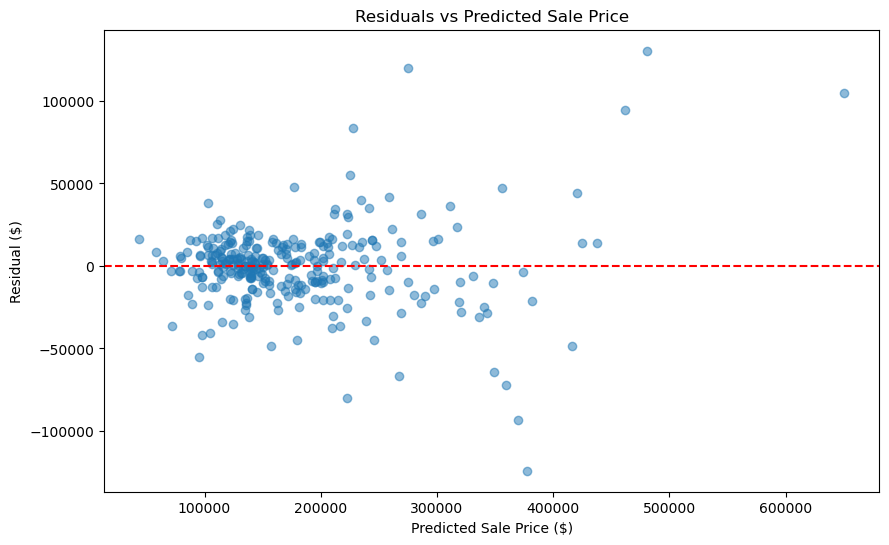

In [48]:
plt.figure(figsize=(10, 6))

plt.scatter(
    residuals["Predicted"],
    residuals["Residual"],
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Sale Price ($)")
plt.ylabel("Residual ($)")
plt.title("Residuals vs Predicted Sale Price")

plt.show()

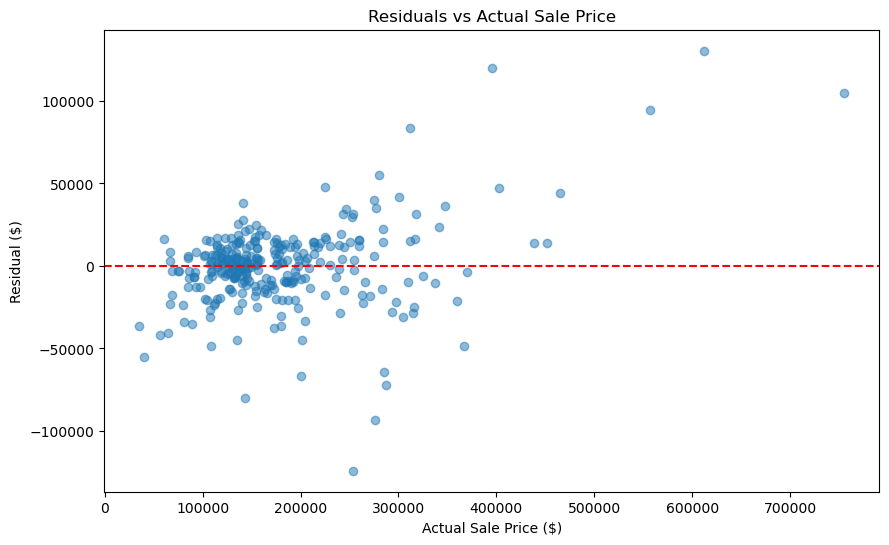

In [49]:
plt.figure(figsize=(10, 6))

plt.scatter(
    residuals["Actual"],
    residuals["Residual"],
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Residual ($)")
plt.title("Residuals vs Actual Sale Price")

plt.show()

In [50]:
residuals["Price Group"] = pd.cut(residuals["Actual"], bins=[0,150000,250000,400000,np.inf],
                                  labels=[
                                    "Under 150k",
                                    "150k-250k",
                                    "250k-400k",
                                    "Over 400k"
                                  ])

price_summary = residuals.groupby("Price Group", observed = True).agg(Count = ("Actual", "size"), Mean_Residuals = ("Residual","mean"),
                                                                      MAE = ("Absolute_Error", "mean"))

price_summary

,Count,Mean_Residuals,MAE
Price Group,,,
Under 150k,139,-3117.324415,11373.070481
150k-250k,105,-384.662202,13345.708036
250k-400k,41,-544.514863,32278.094131
Over 400k,7,64130.111607,64130.111607


The residual analysis suggests that my XGBoost model produces larger absolute prediction errors for higher priced properties. Homes valued below $250,000 have relatively low mean absolute errors, while properties priced between $250,000 and $400,000 have a MAE of approximately $32,278. 

The model performs especially poor on properties valued above $400,000 with a MAE of approximately $64,130 and a positive mean residual of the same magnitude. This suggests that the model underpredicts the sale price of these high value properties in the validation sample. 

However, because only seven observations fall within the highest price range, furhter investigation is needed before concluding that this pattern generalizes to all expensive properties. 

## Conclusion and Future Improvements 

The initial XGBoost model outperformed the mean baseline model, demonstrating that housing characteristics provide useful information for predicting sale prices. However, the large difference between training and validation errors led to further evaluation using cross validation and hyperparameter tuning. Residual analysis was also conducted to investigate large predictin errors and identify housing price ranges that may require additional modeling attention. 

Future improvements will focus on feature engineering, investigating unsual observations, testing alternative model configurations, and comparing results through cross validation. 

The final model will be selected based on evidence gathered throughout these experiments. 